> 📖 Book: [ch02 – Eigen, SVD](../../.claude/skills/ml-knowledge/chapters/ch02-linear-algebra-eigen-svd.md), [ch03 – Least squares](../../.claude/skills/ml-knowledge/chapters/ch03-least-squares-pseudoinverse-tikhonov.md), [ch13 – PCA](../../.claude/skills/ml-knowledge/chapters/ch13-pca-dimensionality-reduction.md) · Prev: [03](03_linear_inversion_problem.ipynb) · Next: [01_linear_regression](../01_linear_regression/01_normal_equations.ipynb)

# Singular Value Decomposition, Low-Rank Structure and Dynamical Systems

A recurring idea across linear algebra, signal processing, statistics and machine learning is that **complex observations can often be represented using a relatively small number of meaningful components**:

- A signal can be represented as a sum of sinusoidal components (§6).
- A matrix can be approximated by a sum of rank-one matrices (§4).
- A dataset can often be described using a few principal directions (§8).
- A dynamical system may have many state variables but only a few dominant modes of behavior (§10).
- A nonlinear system can sometimes be studied through spectral ideas using Koopman operators (§14).

These ideas are related, but they answer different questions:

| Concept | Main question | Section |
|---|---|---|
| Fourier transform / series | Which frequencies make up this signal? | §6 |
| SVD | Which orthogonal input/output directions contribute to this matrix? | §2–§5 |
| PCA | Which directions explain the largest variance in the data? | §8 |
| Attractor theory | What long-term states or sets can system trajectories approach? | §9 |
| Eigenvalue analysis | How do the modes of a linear system evolve? | §11 |
| DMD | Which spatial patterns and temporal rates/frequencies are present in observed dynamics? | §13 |
| Koopman theory | Can nonlinear dynamics be described through the evolution of observables? | §14 |

A useful mental model is to separate three questions, which is also how this notebook is organized:

1. **Structure** (§1–§8): is there a compact, lower-dimensional representation?
2. **Dynamics** (§9–§10): how does the system evolve over time?
3. **Spectral description** (§11–§14): can that evolution be described in terms of modes?

§15 puts everything on one map.

**Notation.** $X \in \mathbb{R}^{n \times m}$ has $m$ columns; the sum index is $k$ and the truncation rank is $r$, so $X_r = \sum_{k=1}^r \sigma_k \mathbf{u}_k \mathbf{v}_k^T$. The algorithms live in `ml.linalg` and `ml.dynamics`.

**Data.** Everything is public and needs no manual setup: the photo ships with scikit-learn (`china.jpg`, by danielbuechele, CC BY 2.0), the digits too, and the ECG is record 00001 of [PTB-XL](https://physionet.org/content/ptb-xl/1.0.3/) (Wagner et al., 2020, CC BY 4.0), downloaded once to `data/external/ptbxl/`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.integrate import solve_ivp
from scipy.linalg import expm
from scipy.signal import spectrogram
from sklearn.datasets import load_digits, load_sample_image
from sklearn.decomposition import PCA

from ml.data.data_loader import PTBXL_LEADS, load_ptbxl_ecg
from ml.dynamics import damped_pendulum, dmd, lorenz, slow_manifold_system, van_der_pol
from ml.linalg import condition_number, energy, low_rank_approx, pca

plt.style.use("seaborn-v0_8-whitegrid")
rng = np.random.default_rng(0)

## 1. Data as a matrix

In science and engineering, data from simulations and experiments is frequently collected in vectors $\mathbf{x}_k \in \mathbb{C}^n$, where the subscript $k$ labels the $k$-th measurement. For instance, $\mathbf{x}_k$ might be an image reshaped into a column vector, the state of a physical system at time point $k$, or a time series $\mathbf{x}_k = \mathbf{x}(k \Delta t)$. The data is then organized into a matrix $X \in \mathbb{C}^{n \times m}$:

$$
X =
\begin{bmatrix}
\mid & \mid & & \mid \\
\mathbf{x}_1 & \mathbf{x}_2 & \cdots & \mathbf{x}_m\\
\mid & \mid & & \mid \\
\end{bmatrix}
$$

The state dimension $n$ is often very large, up to millions or billions of degrees of freedom. The columns of $X$ are called "snapshots", and $m$ is their count. When $n \gg m$ the matrix is "tall and skinny"; when $n \ll m$ it is "short and fat". This same snapshot matrix returns in §10 (1,000 sensors) and §13 (DMD), where the column order starts to matter because it is time.

## 2. The singular value decomposition

The singular value decomposition (SVD) exists for any complex-valued matrix $X \in \mathbb{C}^{n \times m}$:

$$
X = U \Sigma V^*,
$$

where $U \in \mathbb{C}^{n \times n}$ and $V \in \mathbb{C}^{m \times m}$ are unitary: $U U^* = U^* U = I$ and $V V^* = V^* V = I$. The matrix $\Sigma \in \mathbb{R}^{n \times m}$ has real, non-negative entries on its diagonal and zeros elsewhere, and $^*$ is the complex conjugate transpose (a plain transpose $^T$ for real data, which is what most of this notebook uses).

When $n \geq m$, $\Sigma$ has at most $m$ non-zero diagonal elements and can be written as:

$$
\Sigma =
\begin{bmatrix}
\hat{\Sigma} \\
0
\end{bmatrix}.
$$

Hence $X$ is represented exactly by the "economy" SVD:

$$
X = U \Sigma V^* =
\begin{bmatrix}
\hat{U} & \hat{U}^\perp
\end{bmatrix}
\begin{bmatrix}
\hat{\Sigma} \\
0
\end{bmatrix}
V^* =
\hat{U} \hat{\Sigma} V^*,
$$

where the columns of $\hat{U}^\perp$ span the orthogonal complement of the space spanned by $\hat{U}$. The columns of $U$ are the left singular vectors, the columns of $V$ the right singular vectors. The diagonal entries of $\hat{\Sigma} \in \mathbb{R}^{m \times m}$ are the singular values, in descending order, and they quantify the strength of each component:

$$
\sigma_1 \geq \sigma_2 \geq \cdots \geq \sigma_\rho > 0, \qquad \rho = \operatorname{rank}(X).
$$

The rank is the count of non-zero singular values.

In [2]:
X = rng.random((10, 3))
Uhat, Shat, VT = np.linalg.svd(X, full_matrices=False)  # economy SVD
print("shapes:", Uhat.shape, Shat.shape, VT.shape)
print("singular values:", Shat)
print("X == U S V^T:", np.allclose(X, Uhat @ np.diag(Shat) @ VT))
print("U^T U == I:", np.allclose(Uhat.T @ Uhat, np.eye(3)), "| V^T V == I:", np.allclose(VT @ VT.T, np.eye(3)))

shapes: (10, 3) (3,) (3, 3)
singular values: [3.03769663 1.19918042 0.95477153]
X == U S V^T: True
U^T U == I: True | V^T V == I: True


## 3. Closed-form solutions and numerical computation

The SVD is often the *computational* answer to a problem that already has a formula, so it helps to distinguish an analytical solution from a numerical procedure. Consider

$$
\min_{\boldsymbol{\theta}} f(\boldsymbol{\theta}).
$$

A **closed-form solution** is an explicit mathematical expression for the optimum, when one can be derived under the problem's assumptions. A **numerical solution** uses an algorithm to approximate the optimum.

### 3.1 Example: ordinary least squares

$$
\min_{\boldsymbol{\beta}} \|X\boldsymbol{\beta}-\mathbf{y}\|_2^2
$$

Setting the gradient to zero gives the normal equations (derived in [01/01](../01_linear_regression/01_normal_equations.ipynb)):

$$
X^T X\boldsymbol{\beta}=X^T \mathbf{y}
$$

If $X^TX$ is invertible:

$$
\boldsymbol{\beta}^*=(X^TX)^{-1}X^T\mathbf{y}
$$

This is a closed-form expression. In practice, one solves the linear system rather than explicitly forming the inverse.

### 3.2 Why a closed-form solution may still be expensive

Let $X$ have $n$ observations and $p$ features.

- Forming $X^TX$ costs roughly $O(np^2)$.
- Solving a dense $p\times p$ system can cost roughly $O(p^3)$.

So an analytical solution does not automatically imply an efficient or numerically stable computation. Forming $X^TX$ also **squares the condition number**, $\kappa(X^TX) = \kappa(X)^2$, because its singular values are $\sigma_k^2$. QR or SVD-based methods avoid this. With the SVD, the solution reads directly as the pseudo-inverse from [00/03](03_linear_inversion_problem.ipynb):

$$
\boldsymbol{\beta}^* = X^+ \mathbf{y} = V \hat\Sigma^{-1} U^T \mathbf{y}.
$$

A degree-11 polynomial design matrix (see [01/07](../01_linear_regression/07_polynomial_regression.ipynb)) makes the difference visible: the data has an exact solution, so any error is numerical.

In [3]:
t = np.linspace(0, 1, 50)
V_poly = np.vander(t, 12, increasing=True)
beta_true = np.ones(12)
y = V_poly @ beta_true
kappa = condition_number(V_poly)

Q, R = np.linalg.qr(V_poly)
U, s, VT = np.linalg.svd(V_poly, full_matrices=False)
solutions = {
    "normal equations": np.linalg.solve(V_poly.T @ V_poly, V_poly.T @ y),
    "QR": np.linalg.solve(R, Q.T @ y),
    "SVD": VT.T @ (U.T @ y / s),
}
print(f"kappa(X) = {kappa:.1e}, kappa(X^T X) = {condition_number(V_poly.T @ V_poly):.1e}")
for name, beta in solutions.items():
    print(f"{name:>17}: ||beta - beta_true|| = {np.linalg.norm(beta - beta_true):.1e}")

kappa(X) = 1.2e+08, kappa(X^T X) = 1.4e+16
 normal equations: ||beta - beta_true|| = 1.8e-01
               QR: ||beta - beta_true|| = 1.0e-08
              SVD: ||beta - beta_true|| = 7.0e-09


### 3.3 Examples across machine learning

| Model / method | General solution character | Where |
|---|---|---|
| Ordinary least squares | Closed-form under standard conditions | [01/01](../01_linear_regression/01_normal_equations.ipynb) |
| Ridge regression | Closed-form | [00/03](03_linear_inversion_problem.ipynb) |
| PCA | Directly characterized by eigenvalue decomposition or SVD | §8 |
| Logistic regression | Generally requires numerical optimization | [02/02](../02_logistic_regression/02_cost_and_gradient.ipynb) |
| Lasso | Convex, but typically solved with coordinate or proximal methods | |
| Neural networks | Generally non-convex; trained iteratively | [04/01](../04_neural_networks/01_forward_propagation.ipynb) |
| Gaussian mixture models | Often estimated using iterative EM | |

Important distinctions:

- Convexity does **not** guarantee a closed-form solution.
- Having a gradient or first-order condition does **not** mean the equation can be solved explicitly.
- A problem can have a closed-form mathematical solution but still be best computed using numerical linear algebra, as the cell above just showed.

## 4. Low-rank matrix approximation

Suppose $X \in \mathbb{R}^{n \times m}$ contains many measurements. We want a simpler matrix $\hat{X}$ that preserves the important structure of $X$ while having rank no greater than $r$:

$$
\min_{\hat{X}}\|X-\hat{X}\|_F^2 \quad\text{subject to}\quad \operatorname{rank}(\hat{X})\leq r
$$

Here the Frobenius norm measures the total squared reconstruction error:

$$
\|X-\hat{X}\|_F^2 = \sum_{i,j}(X_{ij}-\hat X_{ij})^2
$$

The goal is not necessarily to preserve every entry exactly. It is to preserve as much of the matrix's overall structure as possible using fewer degrees of freedom.

### 4.1 What does rank mean intuitively?

The rank of a matrix is the number of linearly independent directions represented by its columns (equivalently, its rows). A rank-one matrix can be written as an outer product $X=\mathbf{u}\mathbf{v}^T$, where $\mathbf{u}\in\mathbb{R}^n$ and $\mathbf{v}\in\mathbb{R}^m$. Its entries are $X_{ij}=u_i v_j$, so every row is a scaled version of the same vector $\mathbf{v}^T$: the entire matrix is generated by one separable pattern. A low-rank matrix is a sum of a small number of such patterns.

In [4]:
u = np.array([1.0, 2.0, -1.0])
v = np.array([3.0, 0.0, 1.0, 2.0])
rank_one = np.outer(u, v)
print(rank_one)
print("rank:", np.linalg.matrix_rank(rank_one))
print("row 2 / u_2 == v:", np.allclose(rank_one[1] / u[1], v))

[[ 3.  0.  1.  2.]
 [ 6.  0.  2.  4.]
 [-3. -0. -1. -2.]]
rank: 1
row 2 / u_2 == v: True


### 4.2 The SVD as a sum of rank-one matrices

The matrix $X = U \Sigma V^*$ can equivalently be written as a sum of rank-one matrices:

$$
X = \sum_{k=1}^m \sigma_k \mathbf{u}_k \mathbf{v}_k^* = \sigma_1 \mathbf{u}_1 \mathbf{v}_1^* + \sigma_2 \mathbf{u}_2 \mathbf{v}_2^* + \cdots + \sigma_m \mathbf{u}_m \mathbf{v}_m^*,
$$

where $\sigma_1 \geq \sigma_2 \geq \cdots \geq \sigma_m \geq 0$. Each subsequent term is less influential. In many systems the singular values decay quickly, so truncating at rank $r$ gives a good approximation:

$$
X \approx \tilde{X} = \sum_{k=1}^r \sigma_k \mathbf{u}_k \mathbf{v}_k^* = \tilde{U} \tilde{\Sigma} \tilde{V}^*,
$$

where $\tilde{U} \in \mathbb{R}^{n \times r}$, $\tilde{\Sigma} \in \mathbb{R}^{r \times r}$ and $\tilde{V} \in \mathbb{R}^{m \times r}$. Think of a matrix as assembled from layers of patterns: the singular values say how strongly each layer contributes, and keeping only the strongest ones gives a compact approximation. §5 makes those layers visible on a photo.

### 4.3 Why is the truncated SVD optimal?

The Eckart–Young–Mirsky theorem says that the truncated SVD is a best rank-$r$ approximation under both the Frobenius and the spectral norm:

$$
\boxed{\|X-X_r\|_F^2=\sum_{k=r+1}^{\rho}\sigma_k^2}
\qquad
\boxed{\|X-X_r\|_2=\sigma_{r+1}}
$$

The squared Frobenius reconstruction error is exactly the sum of the squared singular values discarded, and among all matrices with rank at most $r$ the truncated SVD minimizes these errors.

### 4.4 Small numerical example

Suppose the singular values are $\sigma=[10,5,2,1]$. For a rank-two approximation, retain 10 and 5 and discard 2 and 1:

$$
\|X-X_2\|_F^2 = 2^2+1^2=5, \qquad \|X\|_F^2 = 10^2+5^2+2^2+1^2=130,
$$

$$
\frac{\|X-X_2\|_F}{\|X\|_F} = \sqrt{\frac{5}{130}} \approx 0.196,
$$

so the rank-two approximation has about 19.6% relative Frobenius error. The cell builds a matrix with exactly these singular values, checks the numbers, and tries to beat Eckart–Young with 10,000 other rank-2 matrices.

In [5]:
sigma = np.array([10.0, 5.0, 2.0, 1.0])
U4, _ = np.linalg.qr(rng.normal(size=(8, 4)))
V4, _ = np.linalg.qr(rng.normal(size=(6, 4)))
X4 = (U4 * sigma) @ V4.T
X4_2 = low_rank_approx(X4, 2)

print("||X - X_2||_F^2 =", round(np.linalg.norm(X4 - X4_2, "fro") ** 2, 6))
print("||X - X_2||_2   =", round(np.linalg.norm(X4 - X4_2, 2), 6), "(sigma_3)")
print("relative error  =", round(np.linalg.norm(X4 - X4_2, "fro") / np.linalg.norm(X4, "fro"), 3))

# rank-2 candidates: the best fit inside a random 2D column space, perturbed around the optimum
candidates = []
for _ in range(10_000):
    Q2, _ = np.linalg.qr(U4[:, :2] + 0.3 * rng.normal(size=(8, 2)))
    candidates.append(np.linalg.norm(X4 - Q2 @ (Q2.T @ X4), "fro") ** 2)
print("best squared error of 10,000 other rank-2 matrices:", round(min(candidates), 3), ">= 5")

||X - X_2||_F^2 = 5.0
||X - X_2||_2   = 2.0 (sigma_3)
relative error  = 0.196


best squared error of 10,000 other rank-2 matrices: 8.937 >= 5


## 5. Example: image compression

A grayscale photo is a matrix, so all of §4 applies directly. Here is `china.jpg`, a public sample image bundled with scikit-learn.

A shape: (427, 640, 3) -> X shape: (427, 640)


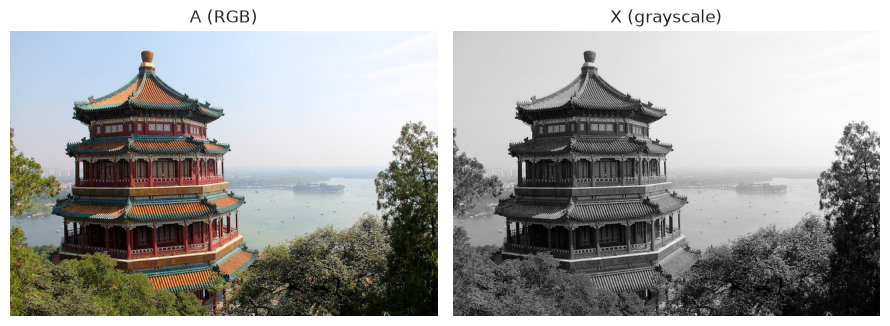

In [6]:
A = load_sample_image("china.jpg")
X = A.mean(axis=-1)  # grayscale: mean of the R, G, B channels
print("A shape:", A.shape, "-> X shape:", X.shape)

fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
ax[0].imshow(A)
ax[1].imshow(X, cmap="gray")
ax[0].set_title("A (RGB)")
ax[1].set_title("X (grayscale)")
for a in ax:
    a.axis("off")
fig.tight_layout()
plt.show()

The layers of §4.2: each $\sigma_k \mathbf{u}_k \mathbf{v}_k^T$ on its own is a separable, blocky pattern of horizontal and vertical structure, and it takes the sum to rebuild the scene.

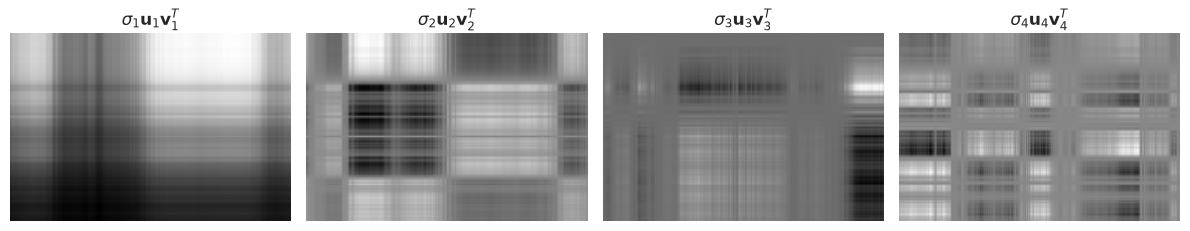

In [7]:
U, s, VT = np.linalg.svd(X, full_matrices=False)
fig, ax = plt.subplots(1, 4, figsize=(12, 2.4))
for k, a in enumerate(ax):
    a.imshow(s[k] * np.outer(U[:, k], VT[k]), cmap="gray")
    a.set_title(rf"$\sigma_{k + 1} \mathbf{{u}}_{k + 1} \mathbf{{v}}_{k + 1}^T$")
    a.axis("off")
fig.tight_layout()
plt.show()

### 5.1 Storage savings

The original matrix stores $nm$ numbers. A rank-$r$ factorization stores approximately

$$
nr+r+rm
$$

numbers, using $\tilde{U}$, $\tilde\Sigma$ and $\tilde{V}$. For example, a $10{,}000\times1{,}000$ matrix has 10,000,000 entries, and a rank-20 factorization stores

$$
10{,}000(20)+20+20(1{,}000)=220{,}020
$$

values, a reduction of about 97.8%. This is useful when the matrix has substantial low-rank structure. The titles below apply the same formula to the photo.

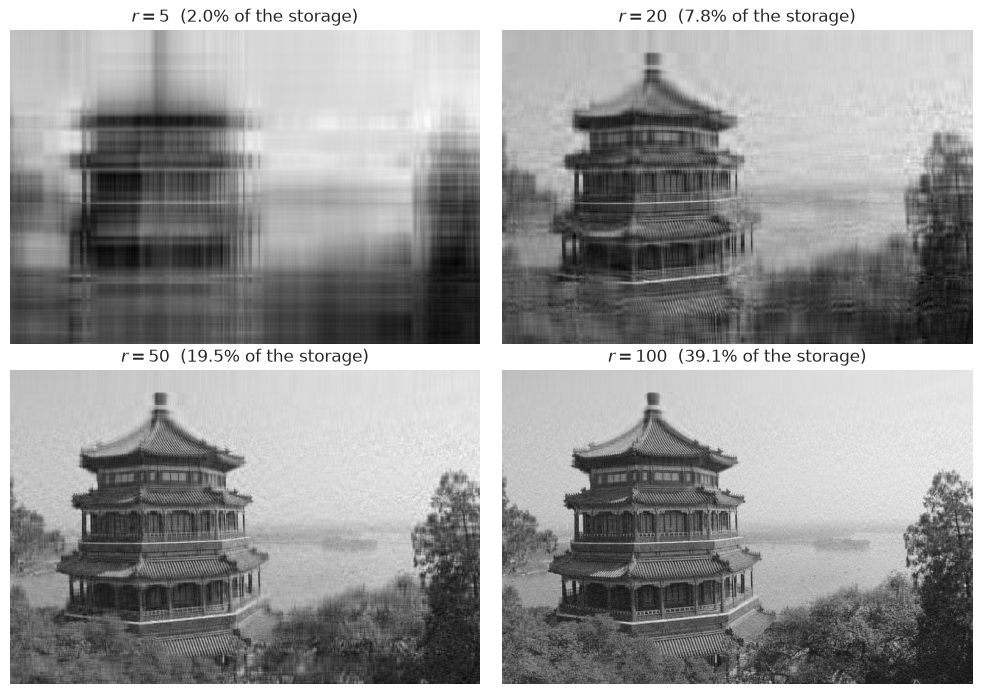

In [8]:
ranks = [5, 20, 50, 100]
fig, ax = plt.subplots(2, 2, figsize=(10, 7))
for a, r in zip(ax.ravel(), ranks, strict=True):
    a.imshow(low_rank_approx(X, r), cmap="gray")
    storage = r * (X.shape[0] + X.shape[1] + 1) / X.size
    a.set_title(f"$r = {r}$  ({storage:.1%} of the storage)")
    a.axis("off")
fig.tight_layout()
plt.show()

The cumulative energy is the Eckart–Young error read the other way round: $\sum_{k \leq r}\sigma_k^2 / \sum_k \sigma_k^2 = 1 - \|X-X_r\|_F^2 / \|X\|_F^2$. The first mode alone passes 90% because the matrix is not centered: it mostly carries the average brightness, which is why PCA (§8) subtracts the mean first. The curve returns in §7 (ECG) and, under the name explained variance, in §8.

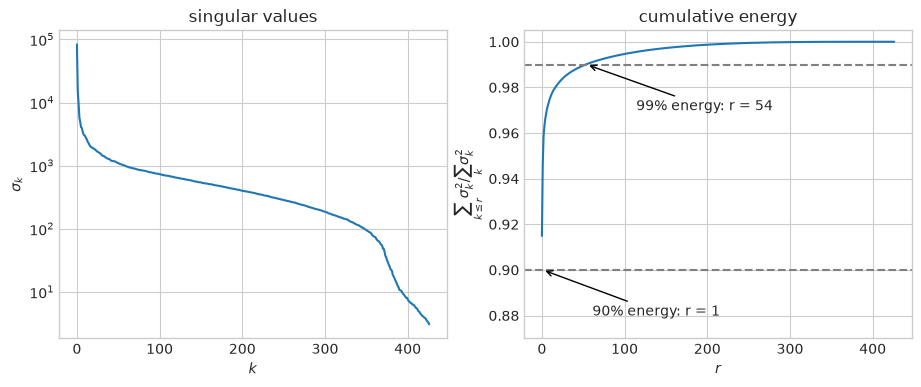

In [9]:
e = energy(s)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].semilogy(s)
ax[0].set(xlabel="$k$", ylabel=r"$\sigma_k$", title="singular values")
ax[1].plot(e)
for level in (0.9, 0.99):
    k = int(np.searchsorted(e, level)) + 1
    ax[1].axhline(level, ls="--", c="gray")
    ax[1].annotate(f"{level:.0%} energy: r = {k}", (k, level), xytext=(k + 60, level - 0.02), arrowprops={"arrowstyle": "->"})
ax[1].set(xlabel="$r$", ylabel=r"$\sum_{k \leq r}\sigma_k^2 / \sum_k \sigma_k^2$", title="cumulative energy", ylim=(0.87, 1.005))
plt.show()

## 6. Analogy: SVD and Fourier series

A Fourier series represents a periodic signal as a weighted sum of sinusoidal basis functions,

$$
x(t)=\sum_k c_k\phi_k(t),
$$

where $\phi_k(t)$ are sinusoidal or complex-exponential basis functions and $c_k$ are Fourier coefficients. The SVD represents a matrix as $X=\sum_k\sigma_k \mathbf{u}_k \mathbf{v}_k^T$. The conceptual correspondence is:

| Fourier series | SVD |
|---|---|
| Signal | Matrix |
| Sinusoidal basis functions | Rank-one matrix components |
| Fourier coefficients | Singular-value weights |
| Partial Fourier reconstruction | Truncated SVD |
| Frequency components | Singular directions / matrix patterns |

Both express a complex object as a sum of simpler components, and both let you stop early, as the square wave shows.

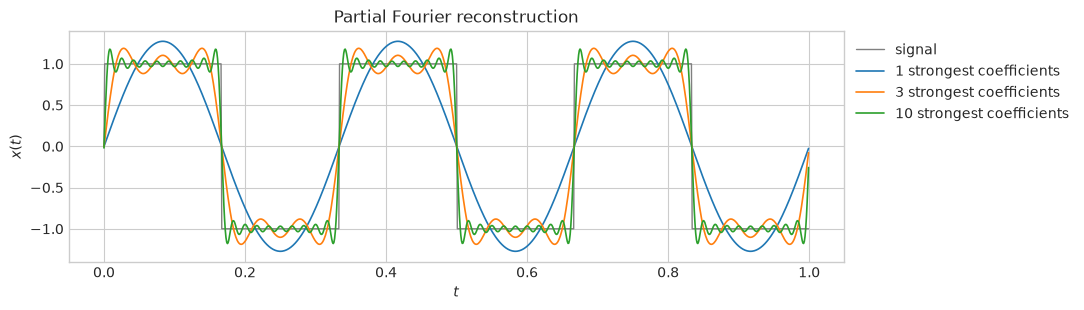

In [10]:
t = np.linspace(0, 1, 1000, endpoint=False)
square = np.sign(np.sin(2 * np.pi * 3 * t))
coefficients = np.fft.rfft(square)
strongest = np.argsort(np.abs(coefficients))[::-1]

fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(t, square, c="gray", lw=1, label="signal")
for K in (1, 3, 10):
    kept = np.zeros_like(coefficients)
    kept[strongest[:K]] = coefficients[strongest[:K]]
    ax.plot(t, np.fft.irfft(kept, len(t)), lw=1.2, label=f"{K} strongest coefficients")
ax.set(xlabel="$t$", ylabel="$x(t)$", title="Partial Fourier reconstruction")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

### 6.1 The important difference

Fourier basis functions are predefined by the choice of frequencies and the domain. The SVD's singular vectors are **data-dependent**: they are calculated from the matrix itself. So:

- Fourier analysis asks: *How much of each frequency component is present?*
- The SVD asks: *Which orthogonal directions and paired patterns best describe this matrix?*

An SVD component is not generally a physical sinusoid. It is a separable matrix pattern.

### 6.2 Connection to audio and spectrograms

The two meet in a magnitude spectrogram $S\in\mathbb{R}^{F\times T}$, where $F$ is the number of frequency bins and $T$ the number of time frames. Applying the SVD, $S=\sum_k\sigma_k \mathbf{u}_k \mathbf{v}_k^T$, for each component:

- $\mathbf{u}_k$ describes a spectral pattern across frequency.
- $\mathbf{v}_k$ describes how the pattern varies over time.
- $\sigma_k$ determines the component's contribution.

This can be useful for compression, denoising, and exploratory analysis. A rank-one component represents a separable frequency-time pattern; it does not necessarily correspond to one physical sound source. The synthetic signal below has two sources, a steady 100 Hz tone and a 300 Hz tone that switches on halfway. Rank 2 rebuilds the spectrogram, but $\mathbf{v}_1$ and $\mathbf{v}_2$ are mixtures, because the sources' activations are not orthogonal and the SVD's factors must be.

energy of the first 3 components: [0.853  0.9977 1.    ]


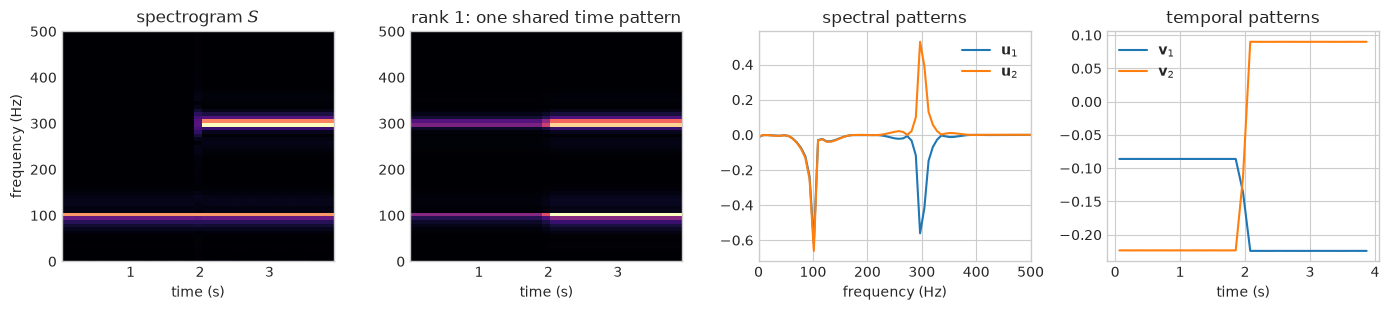

In [11]:
fs = 2000
t = np.arange(0, 4, 1 / fs)
audio = np.sin(2 * np.pi * 100 * t) + 1.5 * (t > 2) * np.sin(2 * np.pi * 300 * t)
freqs, frames, Sxx = spectrogram(audio, fs, nperseg=256, mode="magnitude")
Us, ss, VTs = np.linalg.svd(Sxx, full_matrices=False)
print("energy of the first 3 components:", energy(ss)[:3].round(4))

fig, ax = plt.subplots(1, 4, figsize=(14, 3.2))
ax[0].pcolormesh(frames, freqs, Sxx, shading="auto", cmap="magma")
ax[0].set(xlabel="time (s)", ylabel="frequency (Hz)", ylim=(0, 500), title="spectrogram $S$")
ax[1].pcolormesh(frames, freqs, low_rank_approx(Sxx, 1), shading="auto", cmap="magma")
ax[1].set(xlabel="time (s)", ylim=(0, 500), title="rank 1: one shared time pattern")
for k in range(2):
    ax[2].plot(freqs, Us[:, k], label=f"$\\mathbf{{u}}_{k + 1}$")
    ax[3].plot(frames, VTs[k], label=f"$\\mathbf{{v}}_{k + 1}$")
ax[2].set(xlabel="frequency (Hz)", xlim=(0, 500), title="spectral patterns")
ax[3].set(xlabel="time (s)", title="temporal patterns")
ax[2].legend()
ax[3].legend()
fig.tight_layout()
plt.show()

## 7. Example: 12-lead ECG

Each of the 12 leads of an electrocardiogram records the same heartbeat from a different angle, so the leads are highly correlated. Stacking them as rows of a $12 \times T$ matrix, the SVD finds a handful of orthogonal time patterns (rows of $V^T$) that explain almost all the signal. The first run downloads record 00001 from PTB-XL.

In [12]:
ecg = load_ptbxl_ecg("00001")
fs_ecg = 500
time = np.arange(len(ecg)) / fs_ecg
print("ECG shape (samples, leads):", ecg.shape)

ECG shape (samples, leads): (5000, 12)


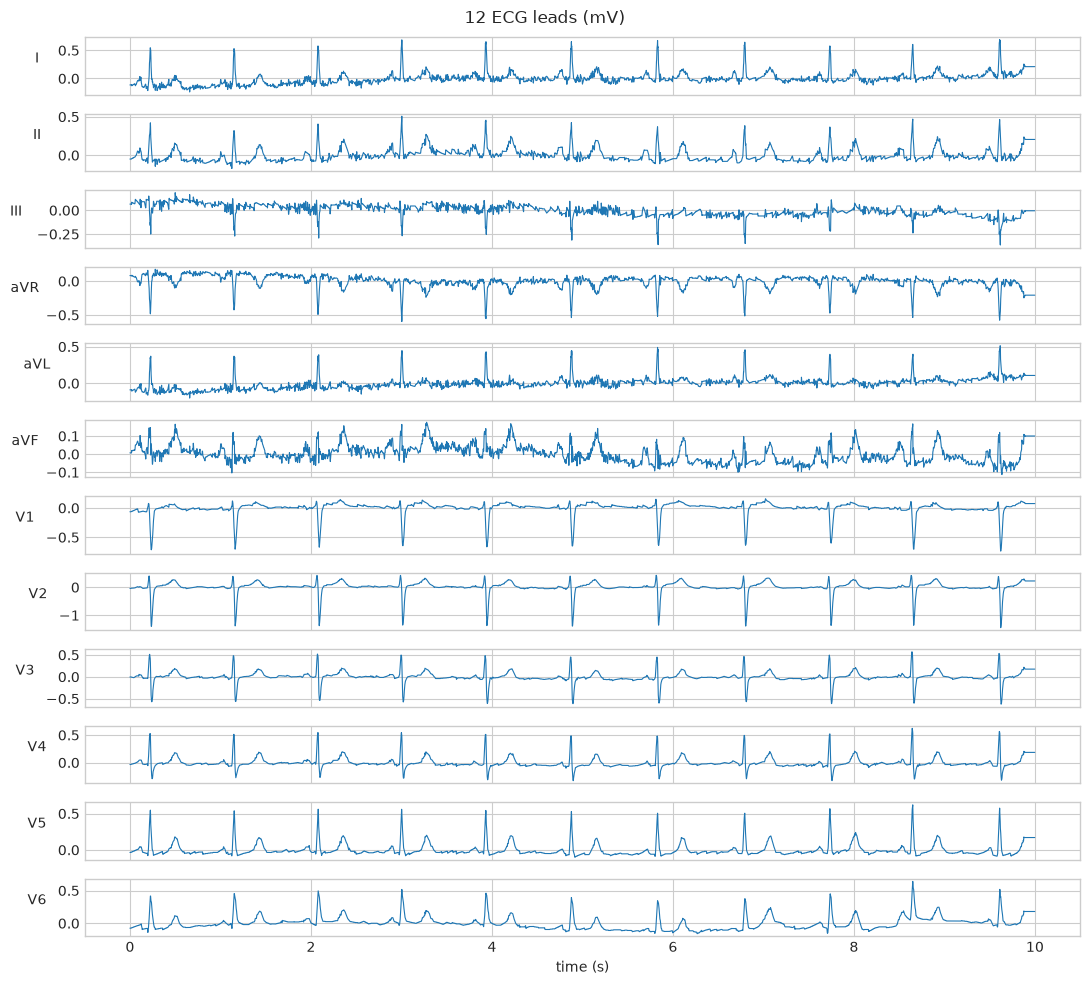

In [13]:
fig, ax = plt.subplots(ecg.shape[1], 1, figsize=(11, 10), sharex=True)
for i, lead in enumerate(PTBXL_LEADS):
    ax[i].plot(time, ecg[:, i], lw=0.8)
    ax[i].set_ylabel(lead, rotation=0, labelpad=15)
ax[-1].set_xlabel("time (s)")
fig.suptitle("12 ECG leads (mV)")
plt.tight_layout()
plt.show()

In [14]:
Uhat, Shat, VThat = np.linalg.svd(ecg.T, full_matrices=False)
print("U:", Uhat.shape, "S:", Shat.shape, "V^T:", VThat.shape)
print("energy captured by the first 3 modes:", energy(Shat)[:3].round(3))
print("singular values:", Shat.round(2))

U: (12, 12) S: (12,) V^T: (12, 5000)
energy captured by the first 3 modes: [0.505 0.892 0.955]
singular values: [19.   16.62  6.7   4.02  3.38  1.63  1.27  0.65  0.03  0.02  0.02  0.02]


Physics puts a hard limit on the rank. Only 8 of the 12 leads are independent, because Einthoven's and Goldberger's relations define the other four from leads I and II: $\text{III} = \text{II} - \text{I}$, $\text{aVR} = -(\text{I}+\text{II})/2$, $\text{aVL} = \text{I} - \text{II}/2$ and $\text{aVF} = \text{II} - \text{I}/2$. That is a constraint of the kind §10.1 discusses, and it should show up as four almost-zero singular values, up to the rounding of the stored samples.

III: max |measured - derived| = 0.0010 mV
aVR: max |measured - derived| = 0.0015 mV
aVL: max |measured - derived| = 0.0015 mV
aVF: max |measured - derived| = 0.0015 mV


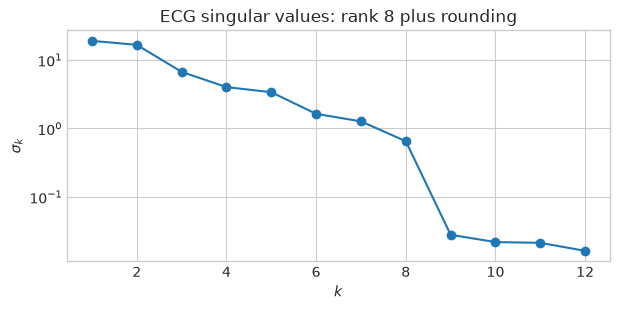

In [15]:
I, II = ecg[:, 0], ecg[:, 1]
derived = {"III": II - I, "aVR": -(I + II) / 2, "aVL": I - II / 2, "aVF": II - I / 2}
for lead, signal in derived.items():
    measured = ecg[:, PTBXL_LEADS.index(lead)]
    print(f"{lead:>3}: max |measured - derived| = {np.abs(measured - signal).max():.4f} mV")

fig, ax = plt.subplots(figsize=(7, 3))
ax.semilogy(range(1, 13), Shat, "o-")
ax.set(xlabel="$k$", ylabel=r"$\sigma_k$", title="ECG singular values: rank 8 plus rounding")
plt.show()

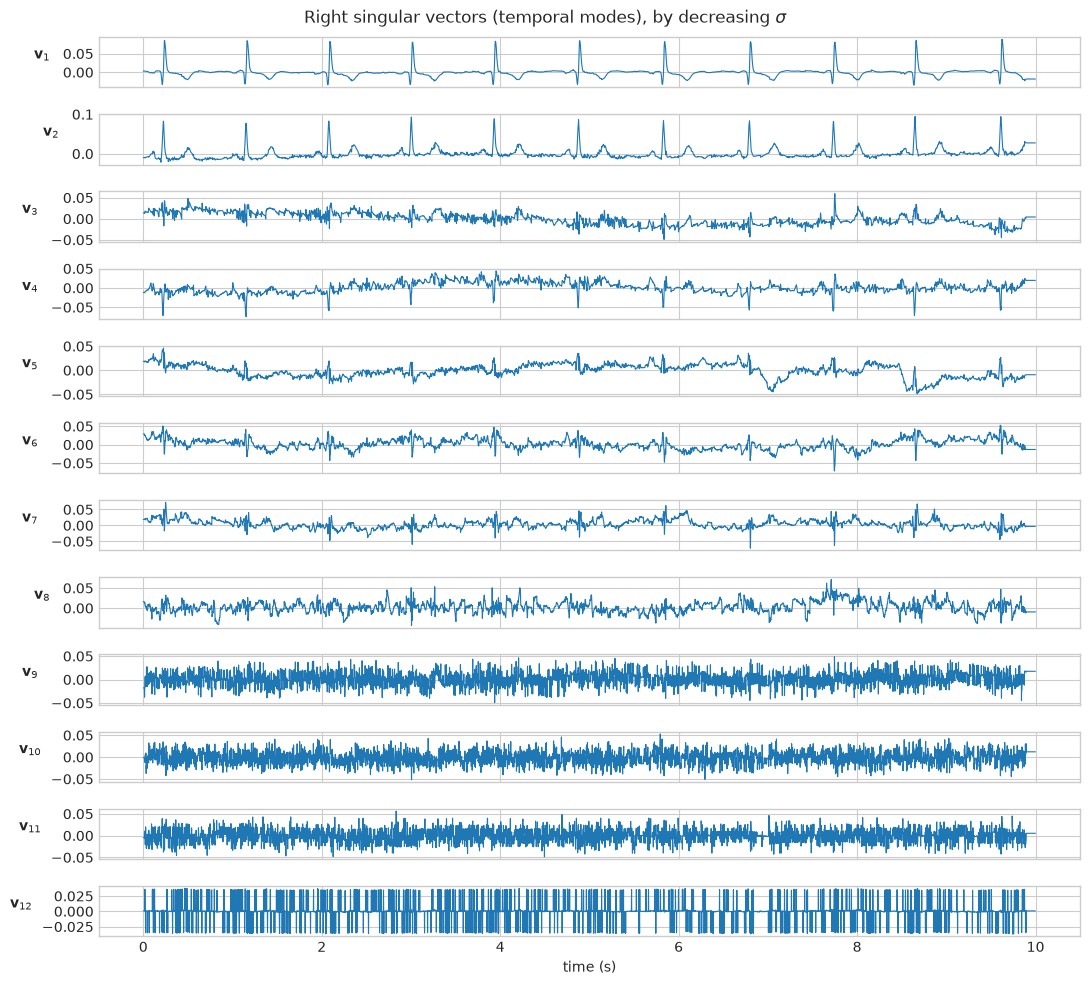

In [16]:
fig, ax = plt.subplots(12, 1, figsize=(11, 10), sharex=True)
for i in range(12):
    ax[i].plot(time, VThat[i, :], lw=0.8)
    ax[i].set_ylabel(f"$\\mathbf{{v}}_{{{i + 1}}}$", rotation=0, labelpad=15)
ax[-1].set_xlabel("time (s)")
fig.suptitle("Right singular vectors (temporal modes), by decreasing $\\sigma$")
plt.tight_layout()
plt.show()

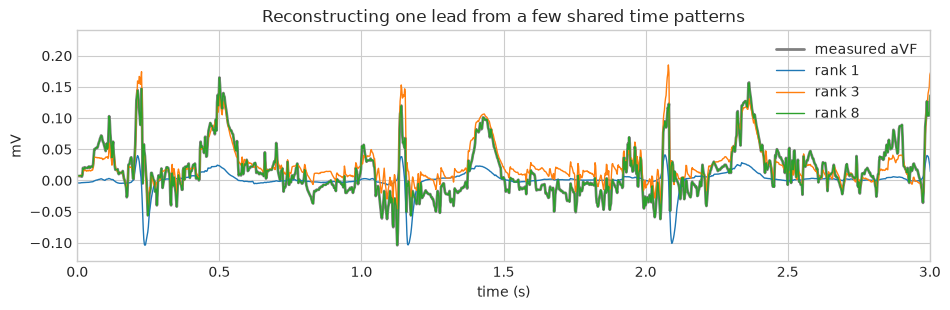

In [17]:
lead = PTBXL_LEADS.index("aVF")
fig, ax = plt.subplots(figsize=(11, 3))
ax.plot(time, ecg[:, lead], c="gray", lw=2, label="measured aVF")
for r in (1, 3, 8):
    ax.plot(time, low_rank_approx(ecg.T, r)[lead], lw=1, label=f"rank {r}")
ax.set(xlabel="time (s)", ylabel="mV", xlim=(0, 3), title="Reconstructing one lead from a few shared time patterns")
ax.legend(loc="upper right")
plt.show()

## 8. PCA as an application of the SVD

Suppose a dataset is $X\in\mathbb{R}^{n\times p}$, where **rows are observations and columns are features**. (Careful: this is the transpose of the snapshot convention of §1.) First, center each feature by subtracting its mean. Then compute $X=U\Sigma V^T$. The covariance matrix is

$$
C=\frac{1}{n-1}X^TX = \frac{1}{n-1}V\Sigma^2V^T.
$$

Therefore:

- The columns of $V$ are the principal directions.
- The covariance eigenvalues are $\sigma_k^2/(n-1)$.
- The squared singular values describe the variance associated with the corresponding principal directions.

The reduced representation using the first $r$ components is

$$
Z=XV_r, \qquad Z\in\mathbb{R}^{n\times r},
$$

which maps the observations from $p$ original features to $r$ principal-component coordinates. Scale matters here: features on larger scales dominate the variance, as in [01/06](../01_linear_regression/06_multivariate_and_feature_scaling.ipynb). The digits below all share the same pixel scale, so centering is enough.

### 8.1 Choosing the number of components

A common criterion is the cumulative explained variance ratio, which is exactly the energy curve of §5:

$$
\mathrm{EVR}(r)= \frac{\sum_{k=1}^{r}\sigma_k^2}{\sum_{k=1}^{\rho}\sigma_k^2}
$$

For example, choose the smallest $r$ that explains at least 95% of the total variance. This is a useful heuristic, not a guarantee that the selected representation is optimal for every downstream prediction task. The book's PCA chapter ([ch13](../../.claude/skills/ml-knowledge/chapters/ch13-pca-dimensionality-reduction.md)) covers the Rayleigh-quotient view; the roadmap has a dedicated `10_pca/` notebook still to do.

X shape: (1797, 64) | components for 95% of the variance: 29
same variances as sklearn: True


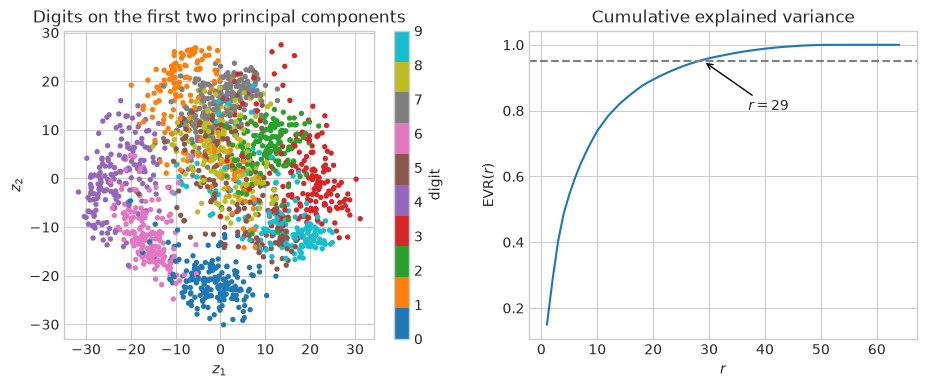

In [18]:
digits = load_digits()
Z, V_r, s_digits = pca(digits.data, 2)
evr = energy(s_digits)
r_95 = int(np.searchsorted(evr, 0.95)) + 1
print("X shape:", digits.data.shape, "| components for 95% of the variance:", r_95)

sk = PCA(2).fit(digits.data)
print("same variances as sklearn:", np.allclose((s_digits**2 / (len(digits.data) - 1))[:2], sk.explained_variance_))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
points = ax[0].scatter(Z[:, 0], Z[:, 1], c=digits.target, cmap="tab10", s=8)
fig.colorbar(points, ax=ax[0], label="digit")
ax[0].set(xlabel="$z_1$", ylabel="$z_2$", title="Digits on the first two principal components")
ax[1].plot(range(1, len(evr) + 1), evr)
ax[1].axhline(0.95, ls="--", c="gray")
ax[1].annotate(f"$r = {r_95}$", (r_95, 0.95), xytext=(r_95 + 8, 0.8), arrowprops={"arrowstyle": "->"})
ax[1].set(xlabel="$r$", ylabel=r"$\mathrm{EVR}(r)$", title="Cumulative explained variance")
plt.show()

## 9. Dynamical systems: state, trajectories and attractors

Now shift from describing the structure of data to describing how a system evolves. A dynamical system has a state vector

$$
\mathbf{x}(t)=
\begin{bmatrix}
x_1(t)\\
x_2(t)\\
\vdots\\
x_n(t)
\end{bmatrix},
$$

whose evolution can be described by an ordinary differential equation:

$$
\frac{d\mathbf{x}}{dt}=\mathbf{f}(\mathbf{x})
$$

The state vector contains the variables needed to describe the system at a given time. A **trajectory** is the path traced by the state through state space as time evolves. For a pendulum, $\mathbf{x}(t) = [\theta(t), \dot\theta(t)]^T$, and a phase portrait plots angular velocity against angular position.

### 9.1 What is an attractor?

An attractor is an invariant set in state space toward which trajectories from nearby initial conditions tend to evolve.

> An attractor describes a set of long-term behaviors that a dynamical system tends to approach.

The set of initial conditions that converge toward a particular attractor is called its **basin of attraction**. There are several common types.

**A. Fixed-point attractor.** A damped pendulum without external forcing eventually stops, so its state approaches the stable equilibrium $\mathbf{x}^*= [0, 0]^T$.

**B. Limit-cycle attractor.** Some systems approach a stable periodic orbit rather than a stationary point. The Van der Pol oscillator is a classical example:

$$
\ddot{x}-\mu(1-x^2)\dot{x}+x=0
$$

For positive $\mu$ it has a stable limit cycle, and different initial conditions converge toward the same closed orbit.

**C. Strange attractor.** The Lorenz system is a classic example (its $\sigma$ is a physical parameter, not a singular value):

$$
\begin{aligned}
\dot{x}&=\sigma(y-x)\\
\dot{y}&=x(\rho-z)-y\\
\dot{z}&=xy-\beta z
\end{aligned}
$$

For certain parameter values, trajectories approach a bounded, geometrically structured set while exhibiting chaotic dynamics:

- The dynamics are deterministic.
- Trajectories remain within a bounded region.
- Long-term behavior is sensitive to initial conditions.
- The trajectory does not settle into a fixed point or a simple periodic orbit.

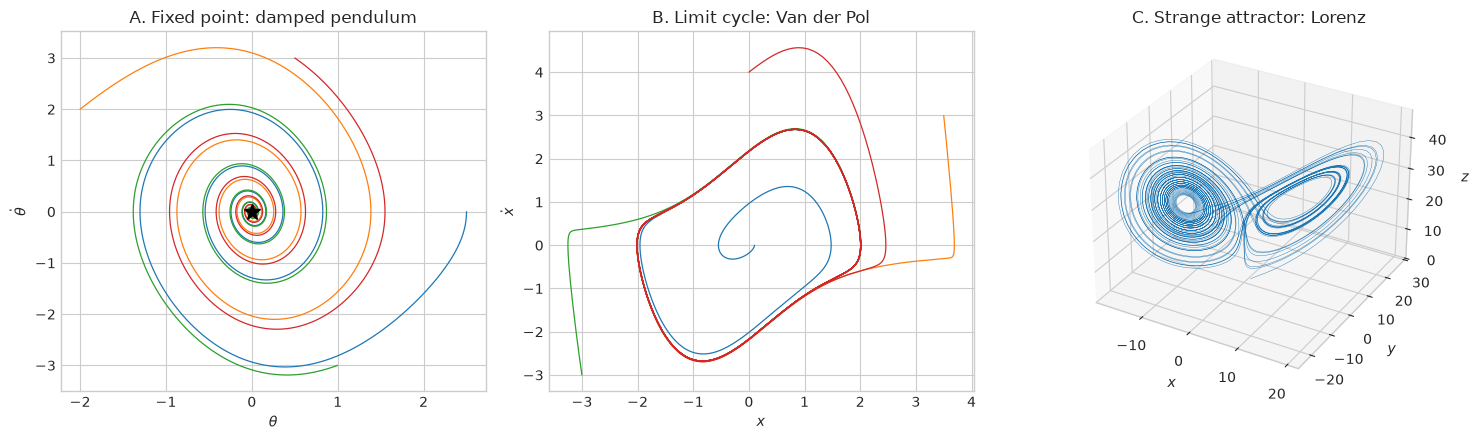

In [19]:
fig = plt.figure(figsize=(15, 4.5))

ax = fig.add_subplot(1, 3, 1)
for x0 in ([2.5, 0.0], [-2.0, 2.0], [1.0, -3.0], [0.5, 3.0]):
    sol = solve_ivp(damped_pendulum, (0, 30), x0, max_step=0.02)
    ax.plot(sol.y[0], sol.y[1], lw=0.9)
ax.plot(0, 0, "k*", ms=12)
ax.set(xlabel=r"$\theta$", ylabel=r"$\dot{\theta}$", title="A. Fixed point: damped pendulum")

ax = fig.add_subplot(1, 3, 2)
for x0 in ([0.1, 0.0], [3.5, 3.0], [-3.0, -3.0], [0.0, 4.0]):
    sol = solve_ivp(van_der_pol, (0, 30), x0, max_step=0.02)
    ax.plot(sol.y[0], sol.y[1], lw=0.9)
ax.set(xlabel="$x$", ylabel=r"$\dot{x}$", title="B. Limit cycle: Van der Pol")

ax = fig.add_subplot(1, 3, 3, projection="3d")
t_lorenz = np.arange(0, 60, 0.01)
lorenz_sol = solve_ivp(lorenz, (0, 60), [1.0, 1.0, 1.0], t_eval=t_lorenz, rtol=1e-9, atol=1e-9)
ax.plot(*lorenz_sol.y, lw=0.3)
ax.set(xlabel="$x$", ylabel="$y$", zlabel="$z$", title="C. Strange attractor: Lorenz")
fig.tight_layout()
plt.show()

**Chaos is not the same as randomness.** A deterministic chaotic system follows fixed equations, but small differences in initial conditions can lead to large differences in future states. Below, two Lorenz trajectories start $10^{-8}$ apart: the gap grows exponentially until it reaches the size of the attractor, and then it can grow no more because the attractor is bounded.

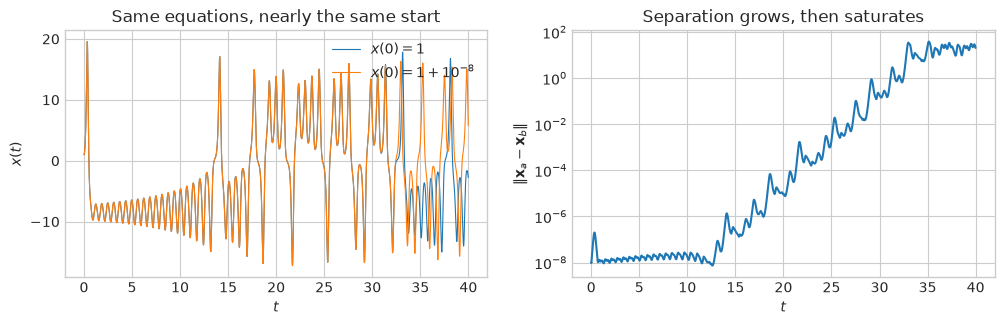

In [20]:
t_short = np.arange(0, 40, 0.01)
a = solve_ivp(lorenz, (0, 40), [1.0, 1.0, 1.0], t_eval=t_short, rtol=1e-11, atol=1e-11).y
b = solve_ivp(lorenz, (0, 40), [1.0 + 1e-8, 1.0, 1.0], t_eval=t_short, rtol=1e-11, atol=1e-11).y

fig, ax = plt.subplots(1, 2, figsize=(12, 3.2))
ax[0].plot(t_short, a[0], lw=0.8, label="$x(0) = 1$")
ax[0].plot(t_short, b[0], lw=0.8, label="$x(0) = 1 + 10^{-8}$")
ax[0].set(xlabel="$t$", ylabel="$x(t)$", title="Same equations, nearly the same start")
ax[0].legend(loc="upper right")
ax[1].semilogy(t_short, np.linalg.norm(a - b, axis=0))
ax[1].set(xlabel="$t$", ylabel=r"$\|\mathbf{x}_a - \mathbf{x}_b\|$", title="Separation grows, then saturates")
plt.show()

## 10. Why can high-dimensional systems have low-dimensional dynamics?

Imagine measuring a physical system with 1,000 sensors, $\mathbf{x}(t)\in\mathbb{R}^{1000}$. It may seem that 1,000 independent degrees of freedom are needed. But the measurements may be strongly related, and the system's trajectory may occupy only a much smaller subset of the full state space. Several mechanisms can produce this.

### 10.1 Constraints and conservation laws

Physical laws restrict which states are possible: conservation of energy, mass, momentum and charge, and geometric constraints (the ECG leads of §7 obey one). For example, a system constrained to a fixed energy level must remain on a surface defined by

$$
E(\mathbf{x})=E_0,
$$

which restricts the accessible state space. The undamped pendulum below stays on such a curve.

A caution: conservation laws do not automatically imply that a system has an attractor. Conservative systems can have very different long-term behavior from dissipative systems. Compare with the spiral of §9.

In [21]:
w2 = 4.0
sol = solve_ivp(damped_pendulum, (0, 30), [2.0, 0.0], args=(0.0, w2), rtol=1e-10, atol=1e-10, max_step=0.01)
E = 0.5 * sol.y[1] ** 2 + w2 * (1 - np.cos(sol.y[0]))
print(f"E(0) = {E[0]:.6f}, max |E(t) - E(0)| = {np.abs(E - E[0]).max():.1e}")

E(0) = 5.664587, max |E(t) - E(0)| = 1.8e-10


### 10.2 Dissipation and stability

Many real systems dissipate energy through friction, resistance, viscosity and other mechanisms. Consider a linear system:

$$
\dot{\mathbf{x}}=A\mathbf{x}, \qquad \mathbf{x}(t)=e^{At}\mathbf{x}(0)
$$

If $A$ is diagonalizable,

$$
\mathbf{x}(t)=\sum_i c_i e^{\lambda_i t}\mathbf{v}_i
$$

where $\lambda_i$ and $\mathbf{v}_i$ are eigenvalues and eigenvectors (§11 looks at this in detail). Suppose $\lambda_1=-0.1$, $\lambda_2=-1$, $\lambda_3=-10$. The modes evolve as $e^{-0.1t}$, $e^{-t}$, $e^{-10t}$, so the third decays much faster than the first. After a transient period, the fast-decaying modes contribute very little and the slower modes dominate.

This is one reason that a high-dimensional system can have a lower-dimensional **effective** description over a particular time interval, and it is where the SVD and dynamics first touch. The cell builds the 1,000-sensor system as three random directions in $\mathbb{R}^{1000}$ and takes the SVD of the snapshot matrix of §1: 1,000 variables, rank 3 overall, and effectively rank 1 once the transient has gone.

numerical rank, whole record: 3


modes for 99.9% of the energy, whole record: 3
modes for 99.9% of the energy, t > 5:       1


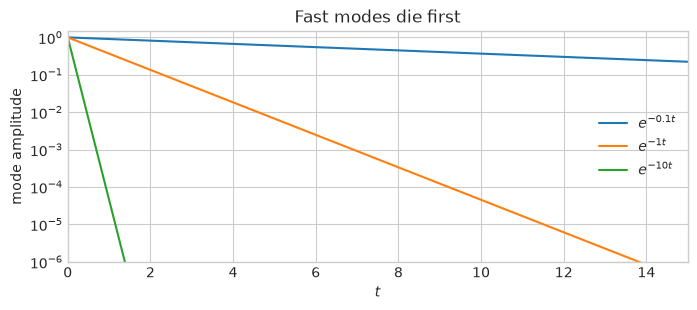

In [22]:
lams = np.array([-0.1, -1.0, -10.0])
directions, _ = np.linalg.qr(rng.normal(size=(1000, 3)))
t = np.linspace(0, 30, 600)
modes = np.exp(np.outer(lams, t))
snapshots = directions @ modes  # 1000 sensors x 600 time instants


def effective_rank(M, level=0.999):
    return int(np.searchsorted(energy(np.linalg.svd(M, compute_uv=False)), level)) + 1


late = t > 5
print("numerical rank, whole record:", np.linalg.matrix_rank(snapshots))
print("modes for 99.9% of the energy, whole record:", effective_rank(snapshots))
print("modes for 99.9% of the energy, t > 5:      ", effective_rank(snapshots[:, late]))

fig, ax = plt.subplots(figsize=(8, 3))
for lam, m in zip(lams, modes, strict=True):
    ax.semilogy(t, m, label=rf"$e^{{{lam:g}t}}$")
ax.set(xlabel="$t$", ylabel="mode amplitude", ylim=(1e-6, 1.5), xlim=(0, 15), title="Fast modes die first")
ax.legend()
plt.show()

### 10.3 Separation of timescales

Some systems contain fast and slow variables. Fast variables may quickly approach relationships determined by the slow variables, and the long-term evolution can then sometimes be approximated using only the slow variables. Related concepts include slow manifolds, center manifolds, singular perturbation theory and adiabatic approximations. This is a deeper mathematical explanation for why some systems can be approximated by fewer effective degrees of freedom.

A small example, which returns in §14:

$$
\dot x_1 = \mu x_1, \qquad \dot x_2 = \lambda (x_2 - x_1^2), \qquad \lambda \ll \mu < 0.
$$

$x_2$ is fast and collapses onto the invariant curve $x_2 = \frac{\lambda}{\lambda - 2\mu}x_1^2$; after that, $x_1$ alone describes the system.

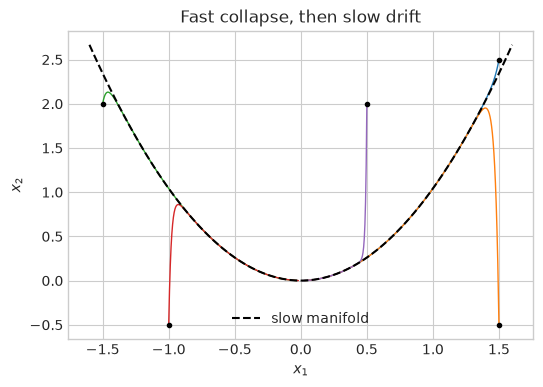

In [23]:
mu, lam = -0.1, -5.0
fig, ax = plt.subplots(figsize=(6, 4))
for x0 in ([1.5, 2.5], [1.5, -0.5], [-1.5, 2.0], [-1.0, -0.5], [0.5, 2.0]):
    sol = solve_ivp(slow_manifold_system, (0, 40), x0, args=(mu, lam), max_step=0.02)
    ax.plot(sol.y[0], sol.y[1], lw=1)
    ax.plot(*x0, "ko", ms=3)
grid = np.linspace(-1.6, 1.6, 100)
ax.plot(grid, lam / (lam - 2 * mu) * grid**2, "k--", label="slow manifold")
ax.set(xlabel="$x_1$", ylabel="$x_2$", title="Fast collapse, then slow drift")
ax.legend()
plt.show()

### 10.4 Important caveat: low-rank data is not automatically a low-dimensional attractor

These ideas are related but not identical.

- **Low rank** is an algebraic property of a matrix or its approximation.
- **Low-dimensional manifold** is a geometric property of a set of states.
- **Attractor** is a dynamical concept involving invariance and attraction under time evolution.

A dataset may be approximately low rank without having been generated by a dynamical system with an attractor (the digits of §8 are not a trajectory of anything). Conversely, a nonlinear attractor may be curved and not well represented by one global low-rank linear subspace. The cell shows the second case: the Van der Pol limit cycle is a one-dimensional curve, but seen through 100 nonlinear sensors the SVD needs many modes, because it can only fit flat subspaces.

In [24]:
cycle = solve_ivp(van_der_pol, (0, 120), [0.1, 0.0], t_eval=np.arange(40, 120, 0.02), rtol=1e-8).y
centers = rng.uniform(-2.5, 2.5, size=(100, 2))
sensors = np.exp(-((cycle[0, None] - centers[:, 0, None]) ** 2 + (cycle[1, None] - centers[:, 1, None]) ** 2) / 0.5)

print("intrinsic dimension of the limit cycle: 1")
print("modes for 99% of the energy, raw state (x, dx/dt):", effective_rank(cycle, 0.99))
print("modes for 99% of the energy, 100 nonlinear sensors:", effective_rank(sensors, 0.99))

intrinsic dimension of the limit cycle: 1
modes for 99% of the energy, raw state (x, dx/dt): 2
modes for 99% of the energy, 100 nonlinear sensors: 15


## 11. Eigenvalues and eigenfunctions of LTI systems

This is where DSP and dynamical systems connect directly. Consider again a continuous-time linear time-invariant state-space system $\dot{\mathbf{x}}=A\mathbf{x}$, with solution $\mathbf{x}(t)=e^{At}\mathbf{x}(0)=\sum_i c_i e^{\lambda_i t}\mathbf{v}_i$ when $A$ is diagonalizable. Each mode has:

- A spatial direction: $\mathbf{v}_i$.
- A temporal evolution: $e^{\lambda_i t}$.

For complex eigenvalues $\lambda_i=\alpha_i+j\omega_i$:

$$
e^{\lambda_i t}=e^{\alpha_i t}e^{j\omega_i t}
$$

The two factors describe:

- $e^{\alpha_i t}$: exponential growth or decay.
- $e^{j\omega_i t}$: oscillation at angular frequency $\omega_i$.

For a real system, complex eigenvalues occur in conjugate pairs and combine to produce real-valued oscillations.

### 11.1 Stability and attractors

If every eigenvalue has negative real part, $\operatorname{Re}(\lambda_i)<0$, then the origin is an asymptotically stable equilibrium,

$$
\lim_{t\to\infty}\mathbf{x}(t)=\mathbf{0},
$$

that is, a fixed-point attractor (case A of §9). The eigenvalues determine how quickly the different modes decay and whether they oscillate, which is a direct connection between eigenvalue analysis and attractor stability. But remember:

- Eigenvalues and eigenvectors characterize modes of a linear operator.
- An attractor describes long-term behavior of a dynamical system.

They are related concepts, not interchangeable ones. Also, the eigenvectors of $A$ are generally not orthogonal, unlike singular vectors, so eigenmodes and SVD modes are different objects.

eigenvalues: [-0.5+2.j -0.5-2.j]
modal sum == expm(A t) x0: True


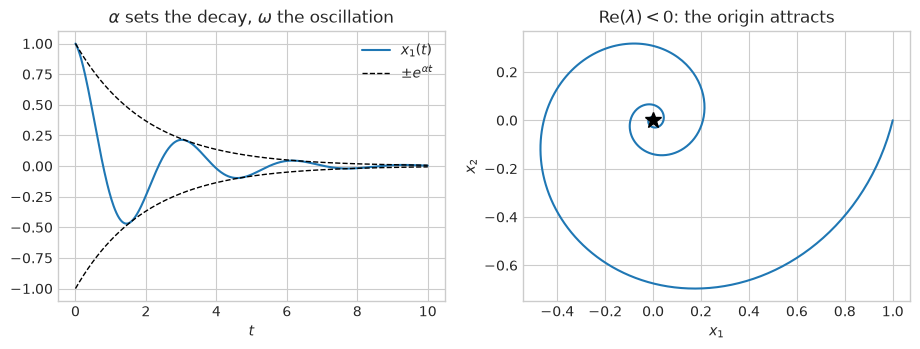

In [25]:
A_lti = np.array([[-0.5, 2.0], [-2.0, -0.5]])
eigenvalues, eigenvectors = np.linalg.eig(A_lti)
print("eigenvalues:", eigenvalues)

x0 = np.array([1.0, 0.0])
c = np.linalg.solve(eigenvectors, x0)
t = np.linspace(0, 10, 500)
modal = (eigenvectors[:, None, :] * (c * np.exp(np.outer(t, eigenvalues)))[None, :, :]).sum(axis=2).real
print("modal sum == expm(A t) x0:", np.allclose(modal[:, -1], expm(A_lti * t[-1]) @ x0))

alpha = eigenvalues[0].real
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(t, modal[0], label="$x_1(t)$")
ax[0].plot(t, np.exp(alpha * t), "k--", lw=1, label=r"$\pm e^{\alpha t}$")
ax[0].plot(t, -np.exp(alpha * t), "k--", lw=1)
ax[0].set(xlabel="$t$", title=r"$\alpha$ sets the decay, $\omega$ the oscillation")
ax[0].legend()
ax[1].plot(modal[0], modal[1])
ax[1].plot(0, 0, "k*", ms=12)
ax[1].set(xlabel="$x_1$", ylabel="$x_2$", title=r"$\mathrm{Re}(\lambda) < 0$: the origin attracts")
plt.show()

### 11.2 Why complex exponentials matter in LTI systems

For an LTI system, complex exponentials are eigenfunctions. If the input is

$$
x(t)=e^{j\omega t},
$$

then the output of a stable LTI system in steady-state is a scaled version

$$
y(t)=H(j\omega)e^{j\omega t},
$$

where $H(j\omega)$ is the frequency response. This explains why Fourier analysis (§6) is so useful for LTI systems: it decomposes signals into functions that the system processes independently, each by a complex gain. For $\dot y = -ay + x$ the response is $H(j\omega) = 1/(a + j\omega)$; the transient of mode $e^{-at}$ dies out (§10.2) and the measured gain matches.

In [26]:
a_lti, w = 1.0, 3.0
sol = solve_ivp(lambda t, y: -a_lti * y + np.exp(1j * w * t), (0, 30), [0j], rtol=1e-10, atol=1e-10)
measured = sol.y[0, -1] / np.exp(1j * w * sol.t[-1])
print("y(t) / x(t) at t = 30:", np.round(measured, 5))
print("H(j omega)           :", np.round(1 / (a_lti + 1j * w), 5))

y(t) / x(t) at t = 30: (0.1-0.3j)
H(j omega)           : (0.1-0.3j)


## 12. Fourier analysis, SVD, eigenmodes and attractors: how they differ

These concepts share the idea of decomposing or characterizing complex behavior, but they have different mathematical roles.

| Concept | What it represents |
|---|---|
| Fourier basis | Predefined oscillatory functions |
| Fourier transform | Frequency content of a signal |
| SVD | Orthogonal matrix directions and weighted rank-one components |
| PCA | Directions of maximum variance in centered data |
| Eigenmodes of a linear system | Spatial directions with characteristic temporal evolution |
| Attractor | Invariant long-term set toward which trajectories approach |
| DMD modes | Data-derived spatial patterns associated with estimated temporal dynamics |
| Koopman eigenfunctions | Observables that evolve by a scalar factor under the Koopman operator |

A chaotic nonlinear system may have a low-dimensional attractor, but its dynamics need not be expressible as a small sum of independent Fourier sinusoids: the Lorenz attractor of §9 has a dimension close to 2, yet the spectrum of $x(t)$ below is broad. Fourier analysis is a spectral representation of signals. Attractor theory is a geometric and dynamical description of long-term system behavior.

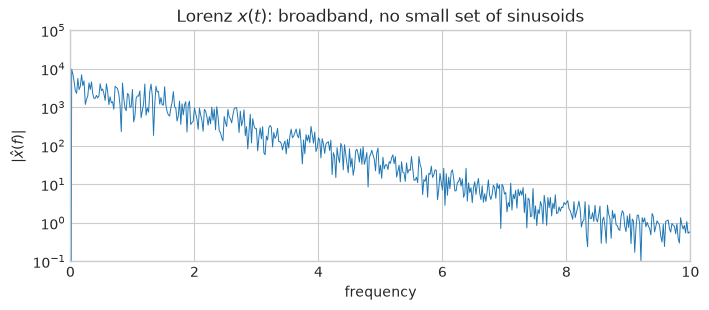

In [27]:
x_lorenz = lorenz_sol.y[0][lorenz_sol.t > 10]
spectrum = np.abs(np.fft.rfft(x_lorenz - x_lorenz.mean()))
frequencies = np.fft.rfftfreq(len(x_lorenz), 0.01)

fig, ax = plt.subplots(figsize=(8, 3))
ax.semilogy(frequencies, spectrum, lw=0.7)
ax.set(xlabel="frequency", ylabel=r"$|\hat{x}(f)|$", xlim=(0, 10), ylim=(1e-1, 1e5), title="Lorenz $x(t)$: broadband, no small set of sinusoids")
plt.show()

## 13. Dynamic Mode Decomposition (DMD): combining SVD and dynamics

DMD connects matrix factorization with temporal evolution. Suppose we observe a system at successive time instants $\mathbf{x}_1,\mathbf{x}_2,\ldots,\mathbf{x}_m$. Construct two snapshot matrices, in the sense of §1:

$$
X=
\begin{bmatrix}
|&|&&|\\
\mathbf{x}_1&\mathbf{x}_2&\cdots&\mathbf{x}_{m-1}\\
|&|&&|
\end{bmatrix},
\qquad
X'=
\begin{bmatrix}
|&|&&|\\
\mathbf{x}_2&\mathbf{x}_3&\cdots&\mathbf{x}_m\\
|&|&&|
\end{bmatrix}
$$

We seek an operator $A$ satisfying approximately $X'\approx AX$. The least-squares estimate, by the pseudo-inverse of §3, is

$$
A\approx X'X^\dagger
$$

where $X^\dagger$ is the Moore–Penrose pseudoinverse. If the snapshots are large, explicitly constructing $A$ may be impractical.

### 13.1 Use the SVD to reduce the problem

Compute $X=U\Sigma V^T$ and retain $r$ dominant singular directions, $X\approx U_r\Sigma_rV_r^T$ (§4). Then construct the reduced operator

$$
\tilde A=U_r^TX'V_r\Sigma_r^{-1},
$$

an $r\times r$ matrix rather than a potentially enormous full-state operator. Compute its eigendecomposition,

$$
\tilde A W=W\Lambda.
$$

The eigenvalues in $\Lambda$ characterize the evolution of the reduced modes. The corresponding DMD modes can be reconstructed in the original observation space. One common exact-DMD expression is

$$
\Phi=X'V_r\Sigma_r^{-1}W.
$$

DMD therefore combines:

1. **SVD:** identify a reduced spatial representation.
2. **Linear operator estimation:** approximate how snapshots evolve.
3. **Eigenvalue analysis** (§11): identify temporal growth/decay and oscillation rates.

For discrete-time eigenvalues $\mu_i$, with sampling interval $\Delta t$, continuous-time rates can be estimated as

$$
\omega_i^{(c)}=\frac{\log(\mu_i)}{\Delta t}.
$$

The real part gives growth or decay, and the imaginary part gives angular frequency, subject to the usual logarithm/aliasing ambiguities.

### Interpretation

A DMD mode can be understood as a spatial pattern whose amplitude evolves with a characteristic rate and frequency. DMD is used in fluid mechanics, coherent-structure analysis, system identification, and data-driven modeling.

The example superimposes two spatial patterns oscillating at $\omega = 2.3$ and $2.8$. The matrix has rank 2, so the SVD compresses it perfectly, yet the SVD modes are mixtures of the two patterns, since it never looks at the column order. DMD uses the time ordering and separates them.

rank of the data: 2
continuous-time rates: [0.+2.8j 0.+2.3j]
relative reconstruction error: 2.7925287372604123e-14


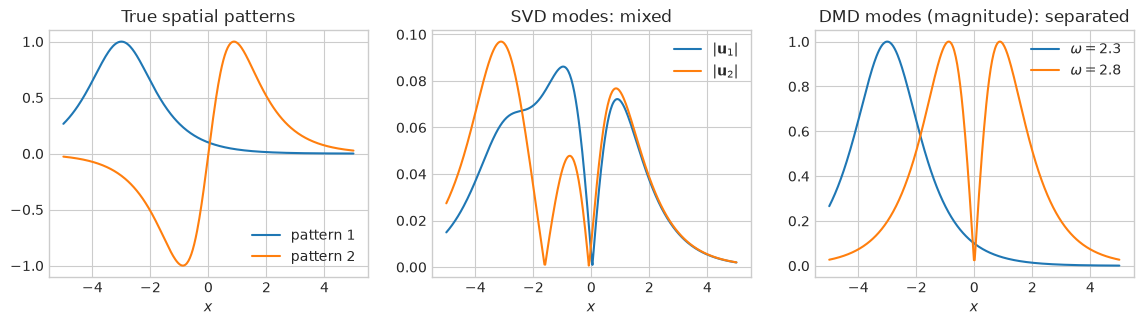

In [28]:
x_grid = np.linspace(-5, 5, 400)
dt = np.pi * 4 / 200
t_dmd = np.arange(200) * dt
pattern_1 = 1 / np.cosh(x_grid + 3)
pattern_2 = 2 / np.cosh(x_grid) * np.tanh(x_grid)
D = np.outer(pattern_1, np.exp(2.3j * t_dmd)) + np.outer(pattern_2, np.exp(2.8j * t_dmd))

print("rank of the data:", np.linalg.matrix_rank(D))
mu_dmd, Phi = dmd(D[:, :-1], D[:, 1:], 2)
rates = np.log(mu_dmd) / dt
print("continuous-time rates:", np.round(rates, 4))

b = np.linalg.lstsq(Phi, D[:, 0], rcond=None)[0]
D_dmd = Phi @ (b[:, None] * np.exp(np.outer(rates, t_dmd)))
print("relative reconstruction error:", np.linalg.norm(D - D_dmd) / np.linalg.norm(D))

U_dmd = np.linalg.svd(D, full_matrices=False)[0]
order = np.argsort(rates.imag)  # 2.3 first, like pattern_1
fig, ax = plt.subplots(1, 3, figsize=(14, 3.2))
ax[0].plot(x_grid, pattern_1, label="pattern 1")
ax[0].plot(x_grid, pattern_2, label="pattern 2")
ax[0].set(xlabel="$x$", title="True spatial patterns")
ax[1].plot(x_grid, np.abs(U_dmd[:, 0]), label=r"$|\mathbf{u}_1|$")
ax[1].plot(x_grid, np.abs(U_dmd[:, 1]), label=r"$|\mathbf{u}_2|$")
ax[1].set(xlabel="$x$", title="SVD modes: mixed")
ax[2].plot(x_grid, np.abs(Phi[:, order[0]] * b[order[0]]), label=r"$\omega = 2.3$")
ax[2].plot(x_grid, np.abs(Phi[:, order[1]] * b[order[1]]), label=r"$\omega = 2.8$")
ax[2].set(xlabel="$x$", title="DMD modes (magnitude): separated")
for a in ax:
    a.legend()
plt.show()

**Caveat:** DMD fits a linear evolution operator in the chosen representation. It can be useful for nonlinear systems, but a finite-dimensional DMD model is not automatically an exact representation of nonlinear dynamics or an attractor. On Lorenz, the one-step error is small, yet the fitted linear model cannot sustain a chaotic attractor: a linear system can only grow, decay or oscillate. The free run below shows it.

one-step relative error: 3.0e-02
|eigenvalues|: [0.99954 0.99728 0.99728]


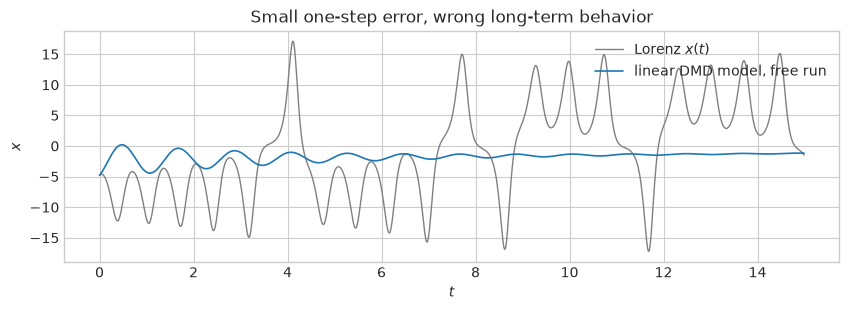

In [29]:
L = lorenz_sol.y[:, lorenz_sol.t > 10]
mu_l, Phi_l = dmd(L[:, :-1], L[:, 1:], 3)
A_l = Phi_l @ np.diag(mu_l) @ np.linalg.pinv(Phi_l)
one_step = np.linalg.norm(A_l @ L[:, :-1] - L[:, 1:]) / np.linalg.norm(L[:, 1:])
print(f"one-step relative error: {one_step:.1e}")
print("|eigenvalues|:", np.abs(mu_l).round(5))

steps = 1500
free_run = np.zeros((3, steps), dtype=complex)
free_run[:, 0] = L[:, 0]
for k in range(steps - 1):
    free_run[:, k + 1] = A_l @ free_run[:, k]

fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(np.arange(steps) * 0.01, L[0, :steps], c="gray", lw=1, label="Lorenz $x(t)$")
ax.plot(np.arange(steps) * 0.01, free_run[0].real, lw=1.2, label="linear DMD model, free run")
ax.set(xlabel="$t$", ylabel="$x$", title="Small one-step error, wrong long-term behavior")
ax.legend(loc="upper right")
plt.show()

## 14. Koopman operators: spectral analysis of nonlinear dynamics

There is an even deeper connection. Consider a nonlinear system $\dot{\mathbf{x}}=\mathbf{f}(\mathbf{x})$. Instead of studying the evolution of the state directly, consider an **observable** $g(\mathbf{x})$: simply a function of the state, which might represent one measured variable or a nonlinear combination of several variables.

The Koopman operator describes how observables evolve under the system's dynamics. For a discrete-time map $F$:

$$
\mathcal{K}g(\mathbf{x})=g(F(\mathbf{x}))
$$

The Koopman operator is linear,

$$
\mathcal{K}(a g_1+b g_2) = a\mathcal{K}g_1+b\mathcal{K}g_2,
$$

even when the underlying state dynamics are nonlinear. A Koopman eigenfunction satisfies

$$
\mathcal{K}\phi_j=\lambda_j\phi_j.
$$

This is conceptually powerful: nonlinear dynamics can be investigated through the spectral properties of a linear operator acting on functions of the state. The complication is that the Koopman operator is generally infinite-dimensional. Practical algorithms such as DMD approximate aspects of its spectral behavior using finite data and finite-dimensional representations. Applications include nonlinear system identification, fluid dynamics, forecasting, data-driven modeling and control theory.

**A case where it closes exactly.** The slow-manifold system of §10.3 is nonlinear in $(x_1, x_2)$, but adding the observable $y_3 = x_1^2$ makes it linear, since $\dot y_3 = 2 x_1 \dot x_1 = 2\mu y_3$:

$$
\frac{d}{dt}
\begin{bmatrix} x_1 \\ x_2 \\ x_1^2 \end{bmatrix}
=
\begin{bmatrix} \mu & 0 & 0 \\ 0 & \lambda & -\lambda \\ 0 & 0 & 2\mu \end{bmatrix}
\begin{bmatrix} x_1 \\ x_2 \\ x_1^2 \end{bmatrix}
$$

So the true spectrum is $\{\mu, \lambda, 2\mu\}$. DMD of §13 on the raw state cannot find it, because it has only two modes to fit a nonlinear system; DMD on the lifted observables recovers it from the same data and forecasts a new initial condition.

true spectrum          : [-1.0, -0.1, -0.05]
DMD on (x1, x2)        : [-0.05   -0.0427]
DMD on (x1, x2, x1^2)  : [-1.   -0.1  -0.05]


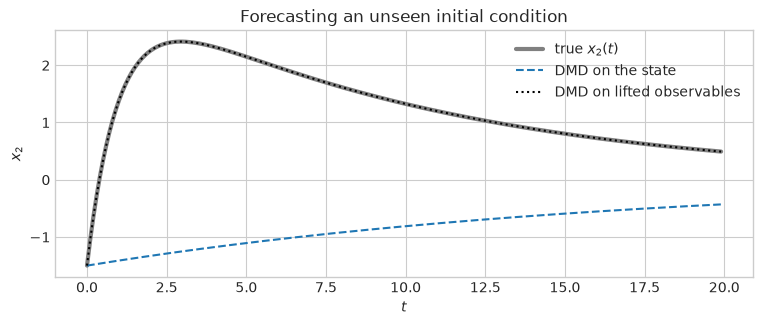

In [30]:
mu, lam, dt_k = -0.05, -1.0, 0.1
t_k = np.arange(0, 20, dt_k)
starts = rng.uniform(-2, 2, size=(10, 2))


def simulate(x0):
    return solve_ivp(slow_manifold_system, (0, t_k[-1]), x0, t_eval=t_k, args=(mu, lam), rtol=1e-10, atol=1e-10).y


def lift(x):
    return np.vstack([x, x[0] ** 2])


runs = [simulate(x0) for x0 in starts]
raw_X = np.hstack([x[:, :-1] for x in runs])
raw_Xp = np.hstack([x[:, 1:] for x in runs])
lift_X = np.hstack([lift(x)[:, :-1] for x in runs])
lift_Xp = np.hstack([lift(x)[:, 1:] for x in runs])

mu_raw, Phi_raw = dmd(raw_X, raw_Xp, 2)
mu_lift, Phi_lift = dmd(lift_X, lift_Xp, 3)
print("true spectrum          :", sorted([mu, lam, 2 * mu]))
print("DMD on (x1, x2)        :", np.sort((np.log(mu_raw.astype(complex)) / dt_k).real).round(4))
print("DMD on (x1, x2, x1^2)  :", np.sort((np.log(mu_lift.astype(complex)) / dt_k).real).round(4))


def forecast(Phi, eigenvalues, x0, steps):
    b0 = np.linalg.lstsq(Phi, x0, rcond=None)[0]
    return (Phi @ (b0[:, None] * eigenvalues[:, None] ** np.arange(steps))).real


x_new = np.array([1.8, -1.5])
truth = simulate(x_new)
raw_pred = forecast(Phi_raw, mu_raw, x_new, len(t_k))
lift_pred = forecast(Phi_lift, mu_lift, lift(x_new[:, None])[:, 0], len(t_k))

fig, ax = plt.subplots(figsize=(9, 3.2))
ax.plot(t_k, truth[1], c="gray", lw=3, label="true $x_2(t)$")
ax.plot(t_k, raw_pred[1], "--", label="DMD on the state")
ax.plot(t_k, lift_pred[1], ":", c="k", label="DMD on lifted observables")
ax.set(xlabel="$t$", ylabel="$x_2$", title="Forecasting an unseen initial condition")
ax.legend()
plt.show()

Finding observables that close like this is the hard part, and for most systems no finite set exists: on Lorenz (§13) adding a few features would not make the attractor linear. That is what "generally infinite-dimensional" costs in practice.

## 15. A unified mental map

```text
                 OBSERVED DATA                         §1
                       |
             Is there redundant structure?
                       |
                SVD / PCA                              §2-§8
                       |
             Low-dimensional features
                       |
          Does the data evolve over time?
                       |
             Dynamical systems                         §9
                       |
          State-space trajectories
                       |
             Long-term behavior
                       |
                  Attractors                           §9-§10
                       |
       How can we characterize the modes?
                       |
           +-----------+-----------+
           |                       |
      Linear systems          Nonlinear systems
           |                       |
   Eigenvalue analysis       Koopman theory            §11, §14
           |                       |
   Modal decomposition      Koopman eigenfunctions
           |                       |
           +-----------+-----------+
                       |
                      DMD                              §13
       (data-driven approximation of modes)
```

A complementary way to organize the ideas:

| Layer | Main concepts | Core question | Section |
|---|---|---|---|
| Data structure | SVD, PCA, low rank | Can the observations be compressed? | §2–§8 |
| Geometry | Manifolds, attractors | Where does the system evolve? | §9, §10 |
| Dynamics | State-space models, stability | How does the state change? | §9, §11 |
| Spectral analysis | Fourier, eigenvalues, Koopman | What modes characterize the evolution? | §6, §11, §14 |
| Data-driven modeling | DMD | Can we infer those modes from observations? | §13 |

## 16. Suggested learning sequence

To build a strong mathematical foundation, study these topics in roughly this order:

1. **State-space representations:** state vectors, trajectories, continuous and discrete systems.
2. **Linear systems:** matrix exponentials, eigenvalues, eigenvectors, modal decomposition.
3. **Stability:** equilibria, asymptotic stability, phase portraits, Lyapunov functions.
4. **Nonlinear dynamical systems:** limit cycles, bifurcations, chaos, strange attractors.
5. **Low-dimensional geometry:** manifolds, center manifolds, slow manifolds, timescale separation.
6. **SVD and PCA:** low-rank approximations and dominant spatial patterns.
7. **DMD:** infer temporal modes from snapshot data.
8. **Koopman theory:** spectral analysis of nonlinear dynamics.

## Final takeaway

The unifying idea is that **the number of variables used to observe a system is not necessarily the number of independent degrees of freedom needed to describe its behavior**.

A high-dimensional dataset may contain redundancy (the 12 leads of §7). A physical system may have fast modes that decay, leaving only a few dominant modes (§10.2). A nonlinear dynamical system may evolve on a low-dimensional attractor embedded in a much larger state space (§10.4).

The SVD and PCA help identify compact structure in observations. Dynamical systems theory explains how states evolve and why trajectories may approach restricted sets. Eigenvalue analysis, DMD and Koopman theory provide ways to characterize the modes of that evolution.

The analogy with Fourier analysis is a useful starting point: all these methods seek meaningful components. The key difference is **what is being decomposed, how the components are obtained, and what mathematical question the decomposition answers**.

Next, the same least-squares problem of §3 opens the regression track: [01_linear_regression](../01_linear_regression/01_normal_equations.ipynb).